# Socratic tutor study: descriptive summary

Loads the exports through `analysis/study_data.py`, so it uses the same participants, exclusions and class groups as `study_analysis.ipynb`. Every table is split by class group (Spain, GSU hotel, GSU invoice), round and condition.

Descriptive only: no significance tests, and no measure of reasoning quality (that needs rubric scoring).

**Privacy:** the exports hold free-text answers but no names, emails or codes. Keep them in approved storage.

In [ ]:
import sys
from pathlib import Path
import pandas as pd

# Run from the analysis/ folder (or the repo root); both work.
ROOT = Path.cwd() if (Path.cwd() / "analysis").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from analysis.study_data import load_study, CONDITION_ORDER

DATA_DIR = ROOT / "analysis" / "data"   # folder with the export_*.csv files
study = load_study(DATA_DIR)            # same filters as every notebook: real participants,
                                        # excluded subjects/cohorts and the excludes file removed

COND = {"scenario_questioning": "Socratic", "direct_chat": "Control"}
ORDER = CONDITION_ORDER
KEYS = ["group", "round_number", "condition"]

# Raw tables, restricted to the participants load_study kept.
part = study.participation
sessions = study.sessions.drop(columns=["group", "round_number", "condition", "session_min"])
turns = study.turns[[c for c in study.turns.columns if not c.endswith("_session")]].drop(
    columns=["group", "round_number", "condition", "study_participation_id",
             "student_words", "ai_words", "latency_s", "failed"], errors="ignore")
attempts = study.attempts.drop(columns=["group", "round_number", "condition", "timed_out", "answer_words"])
attempts = attempts.merge(pd.read_csv(DATA_DIR / "export_assessment_attempt.csv")[["id", "timed_out"]], on="id")
answers = pd.read_csv(DATA_DIR / "export_assessment_answer.csv")
survey = study.survey.drop(columns=["group", "round_number", "condition"], errors="ignore")


## Real participants

In [ ]:
pid_info = part.set_index("id")[KEYS]

def tag(df, key="study_participation_id"):
    return df.merge(pid_info, left_on=key, right_index=True, how="inner")

pd.crosstab([part[k] for k in KEYS], part["status"])

## Time on task (demographics/pretest start to final submit, minutes)

In [3]:
part.dropna(subset=["total_min"]).groupby(KEYS)["total_min"].agg(["count", "mean", "min", "max"]).round(1)

count  mean   min   max
round_number condition                         
1            Control       12  33.2  30.5  36.1
             Socratic      12  34.6  32.1  36.1
2            Control       12  24.6  22.8  27.4
             Socratic      12  27.0  24.4  28.5

## AI interaction

In [4]:
ses = tag(sessions)
for col in ["started_at", "completed_at"]:
    ses[col] = pd.to_datetime(ses[col], utc=True, format="ISO8601")
ses["session_min"] = (ses["completed_at"] - ses["started_at"]).dt.total_seconds() / 60

tt = turns.merge(ses[["id", "study_participation_id"] + KEYS],
                 left_on="tutor_session_id", right_on="id", suffixes=("", "_session"))
if "study_participation_id_session" in tt:
    tt["study_participation_id"] = tt["study_participation_id_session"]
words = lambda s: s.fillna("").astype(str).str.split().str.len()
tt["student_words"] = words(tt["student_message"])
tt["ai_words"] = words(tt["tutor_response"])
tt["latency_s"] = pd.to_numeric(tt["latency_ms"], errors="coerce") / 1000

per_student = tt.groupby(KEYS + ["study_participation_id"]).agg(
    turns=("id", "count"), student_words_total=("student_words", "sum")).reset_index()

summary = pd.concat([
    ses.groupby(KEYS)["session_min"].mean().rename("session_min_mean"),
    per_student.groupby(KEYS)["turns"].mean().rename("turns_mean"),
    tt.groupby(KEYS)["student_words"].median().rename("student_words_per_turn_med"),
    per_student.groupby(KEYS)["student_words_total"].median().rename("student_words_total_med"),
    tt.groupby(KEYS)["ai_words"].median().rename("ai_words_per_turn_med"),
    tt.groupby(KEYS)["latency_s"].median().rename("latency_med_s"),
    tt.groupby(KEYS)["latency_s"].quantile(0.9).rename("latency_p90_s"),
    tt.assign(failed=tt["status"] != "completed").groupby(KEYS)["failed"].sum().rename("failed_turns"),
], axis=1).round(1)
summary

session_min_mean  turns_mean  \
round_number condition                                 
1            Control                16.1         8.6   
             Socratic               17.3        10.2   
2            Control                14.3        10.6   
             Socratic               16.1        10.1   

                        student_words_per_turn_med  student_words_total_med  \
round_number condition                                                        
1            Control                          17.0                    229.0   
             Socratic                         17.0                    250.5   
2            Control                          13.0                    216.0   
             Socratic                         21.0                    262.0   

                        ai_words_per_turn_med  latency_med_s  latency_p90_s  \
round_number condition                                                        
1            Control                    223.0            8.1           13.2   
             Socratic                    53.0           28.3           38.3   
2            Control                    170.0            5.8           11.6   
             Socratic                    50.0           27.2           36.5   

                        failed_turns  
round_number condition                
1            Control               0  
             Socratic              0  
2            Control               0  
             Socratic              0

In [5]:
# How each AI session ended (participant / timeout / evaluator)
pd.crosstab([ses[k] for k in KEYS], ses["end_reason_code"])

end_reason_code         evaluator  participant  timeout
round_number condition                                 
1            Control            0            9        3
             Socratic           1            4        7
2            Control            0           12        0
             Socratic           4            8        0

## Assessments: timeouts and answer length

In [6]:
att = tag(attempts)
att["timed_out"] = att["timed_out"].astype(str).str.lower() == "true"
ans = answers.merge(att[["id", "stage", "study_participation_id"] + KEYS],
                    left_on="assessment_attempt_id", right_on="id", suffixes=("", "_attempt"))
ans["words"] = words(ans["response_text"])
attempt_words = ans.groupby("assessment_attempt_id")["words"].sum()
att["answer_words"] = att["id"].map(attempt_words).fillna(0)

(att.groupby(KEYS + ["stage"])
    .agg(n=("id", "count"), timeouts=("timed_out", "sum"), words_median=("answer_words", "median"))
    .reindex(["pretest", "posttest"], level="stage"))

n  timeouts  words_median
round_number condition stage                               
1            Control   pretest   12         4         135.5
                       posttest  12         7         150.5
             Socratic  pretest   12         1         125.5
                       posttest  12         6         142.0
2            Control   pretest   12         1         154.5
                       posttest  12         0         182.5
             Socratic  pretest   12         4         174.0
                       posttest  12         3         154.0

In [7]:
# Median words per question type (construct)
ans.pivot_table(index=["group", "round_number", "stage", "construct_code"], columns="condition",
                values="words", aggfunc="median").reindex(columns=ORDER)

condition                                   Control  Socratic
round_number stage    construct_code                         
1            posttest counterargument          21.0      19.0
                      evidence_reasoning       38.0      29.5
                      recommendation           87.5      75.0
                      uncertainty_revision     17.5      19.0
             pretest  counterargument          18.0      23.0
                      evidence_reasoning       37.0      37.5
                      recommendation           42.5      45.5
                      uncertainty_revision     17.5      24.5
2            posttest counterargument          33.0      24.5
                      evidence_reasoning       51.5      45.0
                      recommendation           50.0      60.5
                      uncertainty_revision     29.0      31.0
             pretest  counterargument          20.0      25.5
                      evidence_reasoning       24.5      49.0
                      recommendation           49.5      48.0
                      uncertainty_revision     27.0      16.0

## Final survey (Round 2, 1 = strongly disagree … 5 = strongly agree)

In [8]:
ITEMS = {
    "likert_1": "Helped me understand the material",
    "likert_2": "I felt engaged",
    "likert_3": "Made me think carefully",
    "likert_4": "Encouraged me to explain my reasoning",
    "likert_5": "Made me reconsider my thinking",
    "likert_6": "Confident I could explain it to someone",
}
sv = tag(survey)
likert = sv.groupby(["group", "condition"])[list(ITEMS)].mean().T.rename(index=ITEMS).round(2)
likert.loc["n (students)"] = sv.groupby(["group", "condition"]).size()
likert

condition,Control,Socratic,n_control,n_socratic
Helped me understand the material,3.92,3.00,12,12
I felt engaged,3.92,3.33,12,12
Made me think carefully,4.08,3.83,12,12
Encouraged me to explain my reasoning,3.33,4.17,12,12
Made me reconsider my thinking,3.67,4.00,12,12
Confident I could explain it to someone,4.00,4.00,12,12


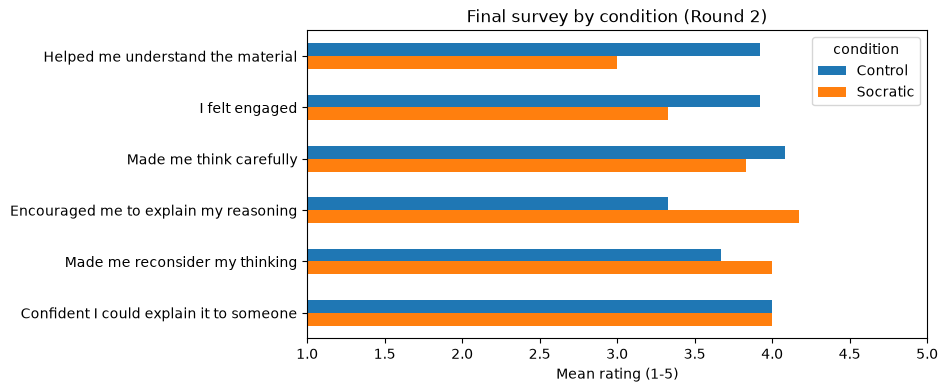

In [10]:
ax = likert.drop(index="n (students)").plot.barh(figsize=(8, 4), xlim=(1, 5))
ax.set_xlabel("Mean rating (1-5)")
ax.set_title("Final survey by condition (Round 2)")
ax.invert_yaxis()

In [11]:
# Written answers, for reading and theme coding
pd.set_option("display.max_colwidth", None)
sv[["group", "condition", "open_response", "open_response_2"]].sort_values(["group", "condition"]).reset_index(drop=True)

,condition,open_response,open_response_2
0,Control,I noticed UI related differences: the table that it tried to present wasn't clear and some of the raw codes were sent rather than texts in the answers,It gave me a framework to work with (only because I asked it explicitly) but it was helpful in developing a reasoning.
1,Control,I mean the main difference is that while using the tool you do not know yet what the next task will be like. So I think I used it in a more thoughtful way. Rather than just getting the results and taking them I rather tried to prepare myself how to approach the next task or the old one. It was more like preparing me solve something rather than solving it for me,"Well it definetely showed me how to reach a solution better and showed me better what I was expected to provide and how I could imagine different solutions. I asked it for its own solution and asked it if mine made sense, based on those answers I reevaluated my old answer."
2,Control,"This one sounded more professional and when i tried to talk about other subjects, it pulled me back to the topic. it was more down to earth and serious.","it reinforced my idea and also found a good additional option, not an alternative. i wanted to do more trials, but ai suggested that while doing trials, the company could still go with the option A."
3,Control,"I did not notice particular differences, but the fact that I grasped very well the topic and I had little uncertainties render my prompts more precise than usual, receiving a sharper output from the AI tool","It gave me empirical standings for calculations that I only approximated, further strengthening the initial ideas I formed on the case. The specific example was the effective reduction in the percentages of option B once we accounted for the fact that the first test had only 65% of the people returning a container"
4,Control,That it doesn't use outside sources and makes assumptions clear.,"It made me more cautious to not give absolute responses, and also to not make too many assumptions even if sometimes they were logical."
5,Control,"Yes, it was more refined and less adapted to my responses. As in, it would not just agree with me instantly. It also added more critical questions than Claude and Gemini usually do.","I considered more variables before reaching a conclusion, although it was the same conclusion, I thought more about my answer."
6,Control,"I think, by nature of the design of the activity, I was much more engaged in an actual discussion with the AI, thinking through options and reasoning, rather than asking a question and simply getting the answer (like so often happens with other AI interactions). I know this is by design - it's the point of the activity, to reason and discuss and expand one's thinking by interacting with it - but it was a difference I definitely observed all the same!","I think it really forced me to think through all possible considerations and helped me to consider factors that I wouldn't have come up with on my own (like providing other scenarios with similar forms of decision-making to help me expand the applicability of the process). I think it's also useful to help me condense my thought process, to focus on the most important factors (like recognizing that with high-risk decisions, where getting it 'wrong' is high-stakes, more caution is wise), and to fully think through different options I may have not considered before."
7,Control,"Yes, it is more contained within the main subject.",It influences my evaluation by encouraging me to go deeper in my explanations.
8,Control,I did not notice any differences.,"If the AI tool brought some relevant limitations to the problem, I tried to consider these and apply them to the second scenario when evaluating the options or what points would make me reconsider one option."
9,Control,"It felt to be reacting a bit more positive about my input. it was also not asking questions in the end that are supposed to make me engage with